# Oubli catastrophique sur MNIST

Un complément à la présentation 14

Marcel Turcotte  
2026-10-31

Un réseau peut apprendre une nouvelle tâche tout en perdant la capacité
d’en résoudre une ancienne : c’est le phénomène d’**oubli
catastrophique** (*catastrophic forgetting*). Ce carnet entraîne un
petit perceptron multicouche (MLP) sur les chiffres MNIST **0–4**, puis
**5–9**. Nous mesurons les deux capacités et comparons l’entraînement
sur les nouvelles données seulement au rejeu d’une petite mémoire
d’anciens exemples d’entraînement (*replay*).

Cet exemple prolonge la discussion de la présentation 14 sur les
difficultés d’entraînement. Le modèle conserve une seule couche de
sortie fixe à **dix logits**; les étiquettes des chiffres gardent leurs
valeurs d’origine. À l’évaluation, les dix classes sont en concurrence.
C’est une forme simple d’**apprentissage incrémental par classes**
(*class-incremental learning*), plutôt qu’une évaluation qui indique au
modèle parmi quels cinq chiffres choisir. Voir
<a href="https://arxiv.org/abs/1904.07734" class="external"
data-icon="true">van de Ven et Tolias (2019)</a>.

## Données et budget d’entraînement reproductible

Nous utilisons la séparation officielle de MNIST entre entraînement et
test. Pour une expérience rapide, chaque chiffre fournit 1 000 images
d’entraînement et 200 de validation, toutes issues de la partition
officielle d’entraînement. Les images du test officiel ne servent pas au
choix des réglages. La première exécution télécharge MNIST avec Keras si
les données ne sont pas déjà en cache.

Les graines fixent les réglages d’initialisation et d’échantillonnage.
Les résultats exacts peuvent quand même varier selon le moteur de calcul
et le matériel; il faut interpréter l’oubli et la rétention mesurés dans
l’exécution réalisée, plutôt qu’attendre des pourcentages identiques sur
tous les systèmes.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import keras

SEED = 42
EPOCHS = 6
STEPS_PER_EPOCH = 40
BATCH_SIZE = 128
LEARNING_RATE = 0.1

keras.utils.set_random_seed(SEED)
(images, labels), (test_images, test_labels) = keras.datasets.mnist.load_data()
data_rng = np.random.default_rng(SEED)
train_indices, validation_indices = [], []
for digit in range(10):
    indices = data_rng.permutation(np.flatnonzero(labels == digit))
    train_indices.extend(indices[:1000])
    validation_indices.extend(indices[1000:1200])

train_images, train_labels = images[train_indices], labels[train_indices]
validation_images = images[validation_indices]
validation_labels = labels[validation_indices]
train_a = (train_images[train_labels < 5], train_labels[train_labels < 5])
train_b = (train_images[train_labels >= 5], train_labels[train_labels >= 5])
validation_a = (validation_images[validation_labels < 5], validation_labels[validation_labels < 5])
validation_b = (validation_images[validation_labels >= 5], validation_labels[validation_labels >= 5])

## Un modèle, dix classes possibles

La couche cachée utilise ReLU et la sortie est linéaire.
`SparseCategoricalCrossentropy(from_logits=True)` reçoit directement les
logits et accepte des étiquettes de chiffres entières. Softmax
convertirait les logits en probabilités; `argmax` donne la même classe
prédite avant ou après softmax.

SGD utilise un taux d’apprentissage constant, sans momentum ni
régularisation. La comparaison porte ainsi sur les données fournies
pendant la seconde phase.

In [3]:
def compile_model(model):
    model.compile(optimizer=keras.optimizers.SGD(learning_rate=LEARNING_RATE),
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True))

def make_model():
    model = keras.Sequential([
        keras.layers.Input(shape=(28, 28)),
        keras.layers.Rescaling(1/255),
        keras.layers.Flatten(),
        keras.layers.Dense(128, activation='relu', kernel_initializer='he_normal'),
        keras.layers.Dense(10)
    ])
    compile_model(model)
    return model

def predicted_classes(model, x):
    logits = keras.ops.convert_to_numpy(model(x, training=False))
    return logits.argmax(axis=1)

def validation_accuracy(model):
    return [np.mean(predicted_classes(model, x) == y)
            for x, y in (validation_a, validation_b)]

## La même boucle d’entraînement, avec ou sans mémoire

Chaque phase a le même nombre de mises à jour et la même taille de lot.
L’échantillonnage avec remise rend ce budget explicite. Sans mémoire,
chaque lot ne contient que des exemples de la nouvelle tâche. Avec
mémoire, la moitié du lot provient de la nouvelle tâche et l’autre
moitié des anciens exemples conservés. Le rejeu modifie donc le mélange
des données dans ce budget fixe.

L’historique retourné consigne l’exactitude de validation des deux
groupes avant l’entraînement et après chaque époque. `train_on_batch`
effectue le passage avant, le calcul des gradients et la mise à jour
SGD; le code NumPy ne fait que constituer les lots.

In [4]:
def train_phase(model, training_data, seed, memory=None):
    rng = np.random.default_rng(seed)
    x, y = training_data
    history = [validation_accuracy(model)]
    new_count = BATCH_SIZE if memory is None else BATCH_SIZE // 2
    for epoch in range(EPOCHS):
        for _ in range(STEPS_PER_EPOCH):
            indices = rng.integers(len(y), size=new_count)
            xb, yb = x[indices], y[indices]
            if memory is not None:
                old_x, old_y = memory
                old_indices = rng.integers(len(old_y), size=BATCH_SIZE-new_count)
                xb = np.concatenate([xb, old_x[old_indices]])
                yb = np.concatenate([yb, old_y[old_indices]])
            model.train_on_batch(xb, yb)
        history.append(validation_accuracy(model))
    return np.asarray(history)

## Phase A : apprendre les chiffres 0–4

In [5]:
sequential_model = make_model()
history_a = train_phase(sequential_model, train_a, seed=101)
weights_after_a = [weight.copy() for weight in sequential_model.get_weights()]
test_predictions_after_a = predicted_classes(sequential_model, test_images)
print('Exactitude de validation après A :')
print(f'  chiffres 0–4 : {history_a[-1, 0]:.1%}')
print(f'  chiffres 5–9 : {history_a[-1, 1]:.1%}')

Exactitude de validation après A :
  chiffres 0–4 : 95.6%
  chiffres 5–9 : 0.0%

Une faible performance sur les chiffres 5–9 est normale à ce stade : ils
n’ont pas encore été des cibles d’entraînement. La référence pour
mesurer l’oubli est la performance sur les chiffres 0–4 **après
l’apprentissage de A**.

## Phase B : nouvelles données seules ou rejeu

La branche séquentielle continue avec ses paramètres appris. La branche
avec rejeu part d’une copie identique de ces paramètres. Les deux
branches utilisent un nouvel optimiseur SGD avec le même taux
d’apprentissage constant; recompiler la branche séquentielle ne
réinitialise pas les poids du modèle.

La mémoire conserve vingt images d’entraînement par ancienne classe,
soit cent images au total. Aucune image de validation ou de test n’y est
placée. Les deux branches ont le même nombre de mises à jour de phase B.

In [6]:
memory_rng = np.random.default_rng(202)
memory_indices = np.concatenate([
    memory_rng.choice(np.flatnonzero(train_a[1] == digit), size=20, replace=False)
    for digit in range(5)
])
memory = (train_a[0][memory_indices], train_a[1][memory_indices])

replay_model = make_model()
replay_model.set_weights(weights_after_a)
compile_model(sequential_model)
history_b = train_phase(sequential_model, train_b, seed=303)
history_replay = train_phase(replay_model, train_b, seed=303, memory=memory)

## Suivre les deux capacités

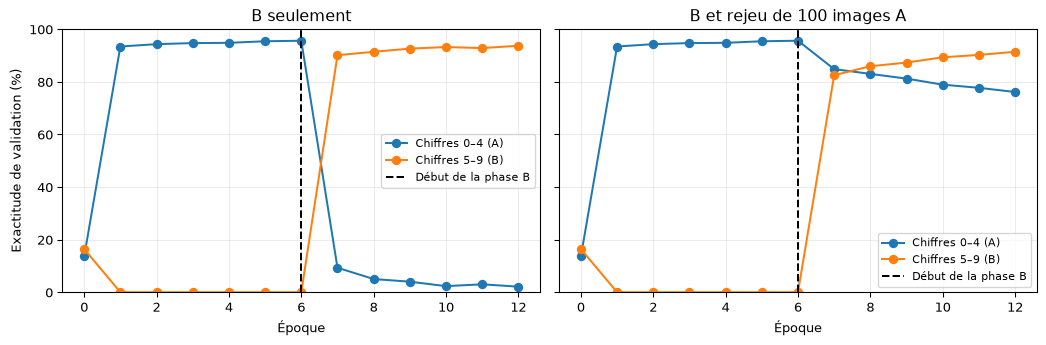

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), sharey=True)
for ax, continuation, title in zip(axes, (history_b, history_replay),
                                  ('B seulement', 'B et rejeu de 100 images A')):
    history = np.vstack([history_a, continuation[1:]])
    epochs = np.arange(len(history))
    ax.plot(epochs, 100*history[:, 0], 'o-', label='Chiffres 0–4 (A)')
    ax.plot(epochs, 100*history[:, 1], 'o-', label='Chiffres 5–9 (B)')
    ax.axvline(EPOCHS, color='black', linestyle='--', label='Début de la phase B')
    ax.set(title=title, xlabel='Époque', ylim=(0, 100), xticks=np.arange(0, 2*EPOCHS+1, 2))
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
axes[0].set_ylabel('Exactitude de validation (%)')
fig.tight_layout()
fig.savefig('catastrophic_forgetting_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()

Les deux panneaux partagent le même historique de phase A. La seconde
phase doit être lue selon deux questions : le modèle apprend-il B et
quelle part de A conserve-t-il? Les courbes de validation décrivent
cette expérience fixe; elles ne servent pas ici à choisir des
hyperparamètres ou un moment d’arrêt.

Le rejeu réduit l’oubli dans cette expérience, sans l’éliminer. Une
partie du budget fixe de mises à jour de phase B est consacrée à A; il
faut donc considérer à la fois la rétention et la performance sur la
nouvelle tâche pour comparer les branches.

## Mesures en fin de phase sur le test officiel

Rapporter les groupes séparément : une exactitude globale peut masquer
une forte perte d’une capacité antérieure. Les dix classes de sortie
restent disponibles pour chaque prédiction.

In [8]:
test_predictions_sequential = predicted_classes(sequential_model, test_images)
test_predictions_replay = predicted_classes(replay_model, test_images)
mask_a = test_labels < 5

def group_accuracies(predictions):
    correct = predictions == test_labels
    return np.array([correct[mask_a].mean(), correct[~mask_a].mean(), correct.mean()])

test_results = {
    'Après A': group_accuracies(test_predictions_after_a),
    'Après B seulement': group_accuracies(test_predictions_sequential),
    'Après B avec rejeu': group_accuracies(test_predictions_replay)
}
print(f"{'Point de sauvegarde':<22} {'A (0–4)':>10} {'B (5–9)':>10} {'Tous chiffres':>12}")
for name, values in test_results.items():
    print(f'{name:<22}' + ''.join(f'{100*value:>10.1f}%' for value in values))
for name in ('Après B seulement', 'Après B avec rejeu'):
    forgetting_pp = 100*(test_results['Après A'][0]-test_results[name][0])
    print(f'Baisse sur A, {name} : {forgetting_pp:.1f} points de pourcentage')

Point de sauvegarde       A (0–4)    B (5–9) Tous chiffres
Après A                     97.1%       0.0%      49.9%
Après B seulement            2.3%      93.9%      46.8%
Après B avec rejeu          79.8%      91.4%      85.4%
Baisse sur A, Après B seulement : 94.8 points de pourcentage
Baisse sur A, Après B avec rejeu : 17.3 points de pourcentage

Ces mesures comparent des points de sauvegarde prédéfinis. Les
prédictions de test de phase A ont été consignées avant l’entraînement
de phase B et ne sont pas recalculées avec les paramètres ultérieurs.

## Les mêmes images, des prédictions différentes

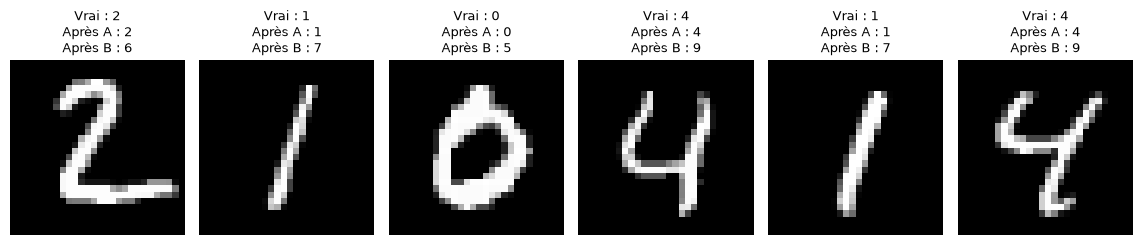

In [9]:
forgotten = np.flatnonzero(mask_a & (test_predictions_after_a == test_labels)
                           & (test_predictions_sequential != test_labels))[:6]
if len(forgotten):
    fig, axes = plt.subplots(1, len(forgotten), figsize=(2*len(forgotten), 2.6), squeeze=False)
    for ax, index in zip(axes[0], forgotten):
        ax.imshow(test_images[index], cmap='gray')
        ax.set_title(f'Vrai : {test_labels[index]}\nAprès A : {test_predictions_after_a[index]}\nAprès B : {test_predictions_sequential[index]}', fontsize=10)
        ax.axis('off')
    fig.tight_layout()
    plt.show()
else:
    print('Aucune image A correctement prédite au départ n\'est devenue incorrecte dans cette exécution.')

Les entrées et leurs étiquettes n’ont pas changé. Les paramètres ont
changé pendant la poursuite de l’entraînement. Dans cet exemple aux
classes disjointes, la baisse peut comprendre un fort biais vers les
classes récentes et des changements des représentations partagées; elle
ne prouve pas que toutes les anciennes représentations utiles ont été
effacées.

## Quelles conséquences pour les modèles déployés?

Faire une prédiction avec un modèle entraîné laisse habituellement ses
poids fixes. L’apprentissage exige un processus explicite de mise à
jour. L’oubli catastrophique peut survenir pendant l’apprentissage en
ligne (*online learning*) ou l’ajustement fin (*fine-tuning*) périodique
par lots, lorsque les nouvelles mises à jour ne protègent pas le
comportement antérieur.

Des réseaux en production peuvent apprendre en ligne;
<a href="https://arxiv.org/abs/2209.07663" class="external"
data-icon="true">Monolith</a> est un exemple de recommandation en temps
réel. Il faut donc concevoir et évaluer soigneusement les mises à jour,
plutôt que conclure que l’apprentissage en ligne serait impossible. La
<a
href="https://developers.google.com/machine-learning/crash-course/production-ml-systems/static-vs-dynamic-training"
class="external" data-icon="true">discussion de Google sur les systèmes
d’apprentissage en production</a> distingue l’entraînement statique et
dynamique.

Le rejeu réintroduit explicitement un objectif sur les anciennes
données. L2 habituelle centrée en zéro pénalise les grands poids; elle
ne préserve pas explicitement les prédictions déjà apprises. Des
méthodes comme la
<a href="https://arxiv.org/abs/1612.00796" class="external"
data-icon="true">consolidation élastique des poids</a> utilisent
d’autres mécanismes pour protéger les acquis. Aucune méthode
d’apprentissage continu n’est ici implémentée ou présentée comme
universellement supérieure.

Pour réfléchir : pourquoi l’exactitude sur B peut-elle augmenter pendant
que celle sur A diminue? Pourquoi la seule exactitude moyenne ne
suffit-elle pas? Qu’est-ce qui change lorsque d’anciens exemples
occupent une partie du budget fixe de mises à jour de phase B?

[Retour à la présentation 14](index.qmd).